# Solar Filament Segmentation 2026 — simple U-Net + Panoptic-DeepLab baseline

One self-contained notebook for **2× T4** (about 2.3 h in total). **Settings → Accelerator → GPU T4 x2**, then *Save & Run All*.
It also runs on one GPU (slower) without any change.

**Two GPUs.** Training uses `nn.DataParallel`: every batch of 16 crops is split 8 + 8 across the two T4s, giving about
1.7× the training steps per hour of a single T4. The 1.75 h budget therefore gives roughly the same amount of training
as 3 h on one GPU. Inference sends the image and its flipped copy to the two GPUs together. Crop targets are built
from pre-computed centres so the 4 CPU cores can keep both GPUs busy.

**Model.** A U-Net (timm ResNet-34 encoder, ImageNet-pretrained if available) with three heads, as in
[Panoptic-DeepLab](https://arxiv.org/abs/1911.10194):
* **semantic**: is this pixel filament? (trained on the *mean* of the annotators' masks, so it learns annotator agreement)
* **center**: a heatmap peaking at each filament's centre of mass
* **offset**: for every filament pixel, the vector pointing to its filament's centre

**Instances.** Panoptic grouping assigns every foreground pixel to the predicted centre its offset points at. Fragments
of one filament that vote for the same centre become one instance. As a fallback and a baseline, the notebook also
tries plain connected components of the foreground. A held-out validation split decides which one is used, scored
with a replica of the competition metric.

**Metric facts this notebook respects.** A prediction is compared with *every* annotator of an image, and any
(prediction, filament) pair with IoU > 0.5 counts as a hit. Overlapping or duplicate masks would be double-counted,
so all masks come from one label image and are disjoint by construction.

In [1]:
import os, json, time, glob, math, random, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import ndimage as ndi
from pycocotools import mask as M
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

DRY = os.environ.get("SFC_DRYRUN") == "1"          # tiny CPU smoke test only; leave unset on Kaggle
FULL = 2048                                          # native image size
RES = 256 if DRY else 1024                           # working resolution (2x down-sampling)
CROP = 128 if DRY else 512                           # training crop
BATCH = 4 if DRY else 16                             # 8 per T4 with DataParallel (use 12 if you hit out-of-memory)
TRAIN_HOURS = 0.01 if DRY else 1.75                  # wall-clock training budget (~= 3 h on a single T4)
ENCODER = "resnet18" if DRY else "resnet34"
LR = 7e-4                                            # slightly higher for the doubled batch
VAL_FRAC = 0.15
SIGMA = 8 * RES / 1024                               # centre-heatmap Gaussian (px at RES)
OFF_SCALE = 64 * RES / 1024                          # offsets are predicted in units of OFF_SCALE px
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(os.environ.get("SFC_WORK", "./work"))
WORK.mkdir(parents=True, exist_ok=True)
T0 = time.time()
N_GPU = torch.cuda.device_count()
torch.backends.cudnn.benchmark = True
print("device:", DEV, "| GPUs:", N_GPU, [torch.cuda.get_device_name(g) for g in range(N_GPU)])
if not DRY and N_GPU < 2: print("!!! only", N_GPU, "GPU visible - choose GPU T4 x2 in the notebook settings for the faster run")

device: cuda | GPUs: 2 ['Tesla T4', 'Tesla T4']


## 1 · Data

In [2]:
CAND = [os.environ.get("SFC_ROOT"), "/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"]
ROOT = next((Path(c) for c in CAND if c and (Path(c) / "train").exists()), None)
if ROOT is None:
    hits = sorted(Path("/kaggle/input").rglob("*Annotations*train*.json"))
    assert hits, "competition data not found under /kaggle/input"
    ROOT = hits[0].parent.parent
ANN = sorted((ROOT / "train").glob("*Annotations*train*.json"))[0]
TRAIN_DIR, TEST_DIR = ROOT / "train" / "train_images", ROOT / "test" / "test_images"

d = json.load(open(ANN))
anns_by_rec = {}
for a in d["annotations"]:
    anns_by_rec.setdefault(a["image_id"], []).append(a)
recs_by_stem = {}
for im in d["images"]:
    recs_by_stem.setdefault(im["file_name"].rsplit(".", 1)[0], []).append(im["id"])
img_path = {p.stem: p for p in TRAIN_DIR.glob("*") if p.suffix.lower() in (".jpeg", ".jpg", ".png")}
stems = sorted(s for s in recs_by_stem if s in img_path)
test_paths = sorted(p for p in TEST_DIR.glob("*") if p.suffix.lower() in (".jpeg", ".jpg", ".png"))
print(f"{len(stems)} train images, {sum(len(recs_by_stem[s]) for s in stems)} annotator records, {len(test_paths)} test images")


def load_image(path):
    """Grayscale frame at RES, a solar-disk mask, and the frame standardised over the disk."""
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (RES, RES), interpolation=cv2.INTER_AREA)
    _, m = cv2.threshold(cv2.GaussianBlur(img, (0, 0), 3), 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    valid = lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA]) if n > 1 else np.ones_like(m, bool)
    valid = ndi.binary_fill_holes(valid)
    valid = cv2.erode(valid.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
    x = img.astype(np.float32)
    x = np.clip((x - x[valid].mean()) / (x[valid].std() + 1e-6), -5, 5) * valid
    return x.astype(np.float16), valid


def record_rles(rid, size):
    """One RLE per annotated filament of one annotator record (polygons are in 2048-px coordinates)."""
    s = size / FULL
    return [M.merge(M.frPyObjects([(np.asarray(p, float) * s).tolist() for p in a["segmentation"]], size, size))
            for a in anns_by_rec.get(rid, [])]


def record_labels(rid):
    lab = np.zeros((RES, RES), np.uint16)
    for k, r in enumerate(record_rles(rid, RES), 1):
        lab[M.decode(r) > 0] = k
    return lab


def centres(lab):
    """Centre of mass of every labelled filament (ids 1..n, in RES pixel coordinates); filaments too small to survive
    the down-sampling are dropped."""
    ids = np.unique(lab); ids = ids[ids > 0]
    if len(ids) == 0:
        return np.zeros((0, 2), np.float32), ids
    return np.array(ndi.center_of_mass(lab > 0, lab, ids), np.float32).reshape(-1, 2), ids


def load_train(s):
    x, valid = load_image(img_path[s])
    labs = [record_labels(r) for r in recs_by_stem[s]]
    soft = np.mean([l > 0 for l in labs], 0)                # fraction of annotators marking each pixel
    soft = np.round(soft * 255).astype(np.uint8)
    fy, fx = np.nonzero(soft[::4, ::4] > 127)
    return x, valid, soft, labs, [centres(l) for l in labs], np.stack([fy * 4, fx * 4], 1)


t = time.time()
with ThreadPoolExecutor(os.cpu_count()) as ex:
    data = list(ex.map(load_train, stems))
IMG = np.stack([d_[0] for d_ in data]); VALID = np.stack([d_[1] for d_ in data])
SOFT = np.stack([d_[2] for d_ in data]); LABS = [d_[3] for d_ in data]
COMS = [d_[4] for d_ in data]; FG = [d_[5] for d_ in data]
del data
print(f"loaded in {time.time() - t:.0f}s | images {IMG.shape}")

# observation-level split (an image's 1-3 annotator records never straddle train / validation)
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(stems))
n_val = max(int(round(VAL_FRAC * len(stems))), 2)
val_idx, tr_idx = np.sort(perm[:n_val]), np.sort(perm[n_val:])
print(f"train {len(tr_idx)} / validation {len(val_idx)} images")

707 train images, 1154 annotator records, 180 test images
loaded in 69s | images (707, 1024, 1024)
train 601 / validation 106 images


## 2 · Training targets (semantic, centre heatmap, offsets)

In [3]:
def crop_targets(lab, com, ids, y0, x0, C):
    """Centre heatmap and offsets (in OFF_SCALE units) for the crop [y0:y0+C, x0:x0+C] of a record's label image.
    Offsets point at the centre of the WHOLE filament, also when the filament is cut by the crop."""
    lab = lab[y0:y0 + C, x0:x0 + C]
    yy, xx = np.mgrid[y0:y0 + C, x0:x0 + C].astype(np.float32)
    heat = np.zeros((C, C), np.float32)
    rr = int(4 * SIGMA) + 2                                # Gaussian is < 3e-4 beyond this
    for cy, cx in com:                                     # Gaussian only inside a small window around each centre
        if y0 - rr < cy < y0 + C + rr and x0 - rr < cx < x0 + C + rr:
            a0, a1 = max(int(cy) - rr - y0, 0), min(int(cy) + rr + 1 - y0, C)
            b0, b1 = max(int(cx) - rr - x0, 0), min(int(cx) + rr + 1 - x0, C)
            if a1 > a0 and b1 > b0:
                g = np.exp(-((yy[a0:a1, b0:b1] - cy) ** 2 + (xx[a0:a1, b0:b1] - cx) ** 2) / (2 * SIGMA ** 2))
                heat[a0:a1, b0:b1] = np.maximum(heat[a0:a1, b0:b1], g)
    off = np.zeros((2, C, C), np.float32)
    on = np.isin(lab, ids) if len(ids) else np.zeros_like(lab, bool)
    if on.any():
        lut = np.zeros(int(ids.max()) + 1, int); lut[ids] = np.arange(len(ids))
        c = com[lut[lab[on]]]
        off[0][on] = (c[:, 0] - yy[on]) / OFF_SCALE
        off[1][on] = (c[:, 1] - xx[on]) / OFF_SCALE
    return heat, off, on


def rot_flip(a, k, f):
    """Spatial rot90 (k times) + optional horizontal flip on the last two axes."""
    a = np.rot90(a, k, axes=(-2, -1))
    return np.ascontiguousarray(np.flip(a, -1) if f else a)


def rot_flip_vectors(off, k, f):
    """Same transform for a (dy, dx) vector field: the arrays move AND the vectors turn with them.
    np.rot90 maps pixel (y, x) -> (W-1-x, y), so a displacement (dy, dx) becomes (-dx, dy); a flip negates dx."""
    off = rot_flip(off, k, f)
    dy, dx = off[0], off[1]
    for _ in range(k % 4):
        dy, dx = -dx, dy
    if f:
        dx = -dx
    return np.ascontiguousarray(np.stack([dy, dx]))


class TrainSet(torch.utils.data.Dataset):
    """Random crops. One annotator record is drawn per sample for the instance targets (centres / offsets); the semantic
    target is always the annotator mean. Targets are computed on the un-rotated crop from pre-computed whole-frame centres,
    then crop and targets are rotated / flipped together (cheap: no full-frame work per sample)."""

    def __init__(self, idx, length):
        self.idx, self.length = np.asarray(idx), length

    def __len__(self):
        return self.length

    def __getitem__(self, k):
        r = np.random
        i = int(r.choice(self.idx))
        j = r.randint(len(LABS[i]))
        lab, (com, ids) = LABS[i][j], COMS[i][j]
        fg = FG[i]
        if len(fg) and r.rand() < 0.7:                    # 70% of crops centred on filament material
            cy, cx = fg[r.randint(len(fg))]
            y0 = int(np.clip(cy - CROP // 2 + r.randint(-CROP // 3, CROP // 3 + 1), 0, RES - CROP))
            x0 = int(np.clip(cx - CROP // 2 + r.randint(-CROP // 3, CROP // 3 + 1), 0, RES - CROP))
        else:
            y0, x0 = r.randint(RES - CROP + 1), r.randint(RES - CROP + 1)
        sl = (slice(y0, y0 + CROP), slice(x0, x0 + CROP))
        heat, off, on = crop_targets(lab, com, ids, y0, x0, CROP)
        rot, flip = r.randint(4), r.rand() < 0.5
        x = rot_flip(IMG[i][sl].astype(np.float32), rot, flip)
        soft = rot_flip(SOFT[i][sl], rot, flip).astype(np.float32) / 255
        valid = rot_flip(VALID[i][sl], rot, flip).astype(np.float32)
        heat, on = rot_flip(heat, rot, flip), rot_flip(on, rot, flip).astype(np.float32)
        off = rot_flip_vectors(off, rot, flip)
        x = (x * r.uniform(0.9, 1.1) + r.normal(0, 0.05)) * valid
        t = lambda a: torch.from_numpy(a[None] if a.ndim == 2 else a)
        return t(x), t(soft), t(heat), t(off), t(on), t(valid)

## 3 · Model: U-Net with three heads

In [4]:
import timm


def make_encoder():
    """ImageNet weights from the internet, else from an attached dataset file, else from scratch (with a warning).
    in_chans=1: timm folds the pretrained RGB filters into one grayscale input channel."""
    kw = dict(features_only=True, in_chans=1)
    try:
        return timm.create_model(ENCODER, pretrained=True, **kw), "timm hub"
    except Exception:
        pass
    for p in sorted(glob.glob("/kaggle/input/**/*", recursive=True)):
        if ENCODER in p.lower() and p.endswith((".safetensors", ".pth", ".bin")):
            try:
                return timm.create_model(ENCODER, pretrained=True, pretrained_cfg_overlay=dict(file=p), **kw), p
            except Exception:
                pass
    return timm.create_model(ENCODER, pretrained=False, **kw), None


def block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


def head(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cin, 3, padding=1), nn.ReLU(inplace=True), nn.Conv2d(cin, cout, 1))


class UNet3(nn.Module):
    def __init__(self, enc):
        super().__init__()
        self.enc = enc
        ch = enc.feature_info.channels()                      # ResNet: strides 2, 4, 8, 16, 32
        w = [256, 128, 64, 32]
        self.dec = nn.ModuleList()
        cin = ch[-1]
        for skip, wo in zip(reversed(ch[:-1]), w):
            self.dec.append(block(cin + skip, wo)); cin = wo
        self.last = block(cin + 1, 16)                          # full resolution, joined with the raw input
        self.sem, self.ctr, self.off = head(16, 1), head(16, 1), head(16, 2)

    def forward(self, x):
        h, w_ = x.shape[-2:]
        p = (-h) % 32, (-w_) % 32
        xp = F.pad(x, (0, p[1], 0, p[0]))
        fs = self.enc(xp)
        y = fs[-1]
        for blk, s in zip(self.dec, reversed(fs[:-1])):
            y = blk(torch.cat([F.interpolate(y, size=s.shape[-2:], mode="bilinear", align_corners=False), s], 1))
        y = self.last(torch.cat([F.interpolate(y, size=xp.shape[-2:], mode="bilinear", align_corners=False), xp], 1))
        out = torch.cat([self.sem(y), self.ctr(y), self.off(y)], 1)
        return out[..., :h, :w_]


enc, src = make_encoder()
print("encoder:", ENCODER, "| pretrained from:", src or "NONE - training from scratch (turn Internet ON or attach weights)")
model = UNet3(enc).to(DEV)
pmodel = nn.DataParallel(model) if N_GPU > 1 else model     # splits every batch across the GPUs; `model` stays the real network
print("training on", max(N_GPU, 1), "device(s)", "with DataParallel" if N_GPU > 1 else "")
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

encoder: resnet34 | pretrained from: timm hub
training on 2 device(s) with DataParallel
24.4 M parameters


## 4 · Training (both GPUs)
Loss = BCE + Dice on the semantic map, MSE on the centre heatmap (weight 200, as in Panoptic-DeepLab),
L1 on offsets over filament pixels. Training runs for a fixed wall-clock budget with a cosine learning-rate schedule.

In [5]:
def loss_fn(out, soft, heat, off, on, valid):
    s = out[:, 0:1]
    bce = (F.binary_cross_entropy_with_logits(s, soft, reduction="none") * valid).sum() / valid.sum().clamp_min(1)
    p = torch.sigmoid(s) * valid
    dice = 1 - (2 * (p * soft).sum() + 1) / (p.sum() + (soft * valid).sum() + 1)
    ctr = ((out[:, 1:2] - heat) ** 2 * valid).sum() / valid.sum().clamp_min(1)
    offl = ((out[:, 2:4] - off).abs() * on).sum() / (2 * on.sum()).clamp_min(1)
    return bce + dice + 200 * ctr + offl, (bce.item(), dice.item(), ctr.item(), offl.item())


loader = torch.utils.data.DataLoader(TrainSet(tr_idx, 10 ** 7), batch_size=BATCH, num_workers=0 if DRY else os.cpu_count(),
                                     worker_init_fn=lambda w: np.random.seed(SEED + w + int(time.time()) % 1000),
                                     pin_memory=DEV.type == "cuda", drop_last=True, prefetch_factor=None if DRY else 4,
                                     persistent_workers=not DRY)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
amp = DEV.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp)
budget = TRAIN_HOURS * 3600
t_start, step, hist = time.time(), 0, []
model.train()
for batch in loader:
    frac = (time.time() - t_start) / budget
    if frac >= 1 or (DRY and step >= 20):
        break
    for g in opt.param_groups:
        g["lr"] = LR * min(1.0, (step + 1) / 300) * (0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(frac, 1))))
    x, soft, heat, off, on, valid = (b.to(DEV, non_blocking=True) for b in batch)
    with torch.autocast(device_type=DEV.type, enabled=amp):
        out = pmodel(x)                                 # batch split across both T4s
    loss, parts = loss_fn(out.float(), soft, heat, off, on, valid)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update()
    hist.append([loss.item(), *parts]); step += 1
    if step % 500 == 0 or (DRY and step % 5 == 0):
        m = np.mean(hist[-500:], 0)
        print(f"step {step} | {(time.time() - t_start) / 60:.0f} min | {step * BATCH / (time.time() - t_start):.1f} crops/s | loss {m[0]:.4f} (bce {m[1]:.4f} dice {m[2]:.3f} "
              f"ctr {m[3]:.5f} off {m[4]:.3f})", flush=True)
torch.save(model.state_dict(), WORK / "unet3.pt")             # plain state_dict (no 'module.' prefix)
print(f"trained {step} steps in {(time.time() - t_start) / 3600:.2f} h")

step 500 | 12 min | 11.4 crops/s | loss 1.8402 (bce 0.1217 dice 0.652 ctr 0.00391 off 0.283)
step 1000 | 23 min | 11.7 crops/s | loss 0.8936 (bce 0.0249 dice 0.320 ctr 0.00169 off 0.211)
step 1500 | 34 min | 11.8 crops/s | loss 0.8340 (bce 0.0240 dice 0.304 ctr 0.00157 off 0.192)
step 2000 | 45 min | 11.9 crops/s | loss 0.7787 (bce 0.0229 dice 0.292 ctr 0.00148 off 0.167)
step 2500 | 56 min | 11.9 crops/s | loss 0.7384 (bce 0.0219 dice 0.282 ctr 0.00140 off 0.155)
step 3000 | 67 min | 11.9 crops/s | loss 0.7069 (bce 0.0218 dice 0.277 ctr 0.00133 off 0.143)
step 3500 | 78 min | 11.9 crops/s | loss 0.6781 (bce 0.0211 dice 0.271 ctr 0.00127 off 0.133)
step 4000 | 90 min | 11.9 crops/s | loss 0.6505 (bce 0.0205 dice 0.263 ctr 0.00123 off 0.121)
step 4500 | 101 min | 11.9 crops/s | loss 0.6504 (bce 0.0206 dice 0.263 ctr 0.00122 off 0.123)
trained 4696 steps in 1.75 h


## 5 · Inference, instance extraction, and the competition metric

In [6]:
@torch.no_grad()
def predict(x, valid):
    """Semantic probability (with horizontal-flip TTA), centre heatmap and offsets (px) at RES."""
    model.eval()
    t = torch.from_numpy(x.astype(np.float32) * valid)[None, None].to(DEV)
    with torch.autocast(device_type=DEV.type, enabled=amp):
        o = pmodel(torch.cat([t, torch.flip(t, (-1,))])).float()   # image + flipped copy: one per GPU
    o1, o2 = o[0:1], torch.flip(o[1:2], (-1,))
    sem = 0.5 * (torch.sigmoid(o1[0, 0]) + torch.sigmoid(o2[0, 0]))
    return (sem.cpu().numpy() * valid).astype(np.float32), o1[0, 1].cpu().numpy(), o1[0, 2:4].cpu().numpy() * OFF_SCALE


def find_centers(ctr, thr=0.1, k=7, topk=80):
    t = torch.from_numpy(ctr)[None, None]
    peak = (t == F.max_pool2d(t, k, 1, k // 2)) & (t > thr)
    ys, xs = np.nonzero(peak[0, 0].numpy())
    order = np.argsort(-ctr[ys, xs])[:topk]
    return np.stack([ys[order], xs[order]], 1).astype(np.float32)


def instances(sem, ctr, off, valid, mode, thr, min_area=40 * (RES / 1024) ** 2, max_dist=48 * RES / 1024):
    """Label image (0 = background) of disjoint instances + mean-probability score per label.
    mode 'cc'       : connected components of the foreground (small closing first)
    mode 'panoptic' : each foreground pixel joins the predicted centre nearest to (pixel + offset); pixels that point
                      nowhere near a centre fall back to connected components."""
    fg = (sem >= thr) & valid
    fg = cv2.morphologyEx(fg.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8)).astype(bool) & valid
    lab = np.zeros(sem.shape, np.int32)
    if mode == "panoptic":
        c = find_centers(ctr)
        ys, xs = np.nonzero(fg)
        if len(c) and len(ys):
            vy, vx = ys + off[0, ys, xs], xs + off[1, ys, xs]
            best = np.empty(len(ys), int); dmin = np.empty(len(ys), np.float32)
            for a in range(0, len(ys), 200_000):                     # chunked nearest-centre search
                d2 = (vy[a:a + 200_000, None] - c[None, :, 0]) ** 2 + (vx[a:a + 200_000, None] - c[None, :, 1]) ** 2
                best[a:a + 200_000] = d2.argmin(1); dmin[a:a + 200_000] = d2.min(1)
            ok = dmin <= max_dist ** 2
            lab[ys[ok], xs[ok]] = best[ok] + 1
    rest = fg & (lab == 0)
    if rest.any():
        n, cc = cv2.connectedComponents(rest.astype(np.uint8), connectivity=8)
        lab[rest] = cc[rest] + lab.max()
    ids, inv = np.unique(lab, return_inverse=True)
    lab = inv.reshape(lab.shape).astype(np.int32)                   # relabel 0..K
    n = int(lab.max())
    if n == 0:
        return lab, np.zeros(0)
    idx = np.arange(1, n + 1)
    area = ndi.sum(np.ones_like(sem), lab, idx)
    score = np.asarray(ndi.mean(sem, lab, idx))
    small = idx[area < min_area]
    if len(small):
        lab[np.isin(lab, small)] = 0
        score[small - 1] = -1                                       # removed
    return lab, score


def to_rles(lab, keep, sem=None, thr=None, size=None):
    """RLEs of the kept labels, optionally at a larger size: nearest-neighbour labels, trimmed by the bilinearly
    up-sampled probability so boundaries follow the map instead of 2x2 blocks. Disjoint by construction."""
    if size and size != lab.shape[0]:
        ix = (np.arange(size) * lab.shape[0]) // size
        lab = lab[ix][:, ix]
        if sem is not None:
            lab = lab * (cv2.resize(sem, (size, size), interpolation=cv2.INTER_LINEAR) >= thr)
    out = []
    for k in keep:
        m = lab == k
        if m.any():
            out.append(M.encode(np.asfortranarray(m.astype(np.uint8))))
    return out


def pq(gt, preds):
    """Competition metric: every annotator record is scored separately against the image's predictions, then pooled.
    hit = IoU > 0.5 for each (gt, prediction) cell; PQ = sum IoU(hits) / (TP + FP/2 + FN/2)."""
    S = TP = FP = FN = 0.0
    for rid, gts in gt.items():
        pr = preds.get(rid.split("-", 1)[1], [])
        if not gts:
            FP += len(pr); continue
        if not pr:
            FN += len(gts); continue
        iou = np.asarray(M.iou(pr, gts, [0] * len(gts))).T
        hit = iou > 0.5
        S += iou[hit].sum(); TP += hit.sum(); FP += (hit.sum(0) == 0).sum(); FN += (hit.sum(1) == 0).sum()
    den = TP + 0.5 * FP + 0.5 * FN
    return dict(pq=S / den if den else 0.0, sq=S / TP if TP else 0.0, dq=TP / den if den else 0.0, tp=int(TP), fp=int(FP), fn=int(FN))


def select(score, min_score):
    keep = np.flatnonzero(score >= min_score) + 1
    if len(keep) == 0 and (score >= 0).any():                       # every image has >= 1 filament in training
        keep = np.array([int(np.argmax(score)) + 1])
    return keep.tolist()

## 6 · Validation: panoptic grouping vs connected components, thresholds

In [7]:
t = time.time()
val_out = {i: predict(IMG[i], VALID[i]) for i in val_idx}
gt_res = {r: record_rles(r, RES) for i in val_idx for r in recs_by_stem[stems[i]]}
rows = []
for mode in ("cc", "panoptic"):
    for thr in (0.3, 0.4, 0.5):
        built = {i: instances(*val_out[i], VALID[i], mode, thr) for i in val_idx}
        enc_ = {i: {int(k): M.encode(np.asfortranarray((b[0] == k).astype(np.uint8))) for k in np.unique(b[0]) if k > 0}
                for i, b in built.items()}
        for ms in (0.0, 0.3, 0.4, 0.5, 0.6):
            preds = {stems[i]: [enc_[i][k] for k in select(built[i][1], ms) if k in enc_[i]] for i in val_idx}
            rows.append(dict(mode=mode, thr=thr, min_score=ms, **pq(gt_res, preds)))
tab = pd.DataFrame(rows).sort_values("pq", ascending=False).reset_index(drop=True)
print(tab.head(10).to_string(index=False))
print("\nbest per mode:\n" + tab.groupby("mode").head(1).to_string(index=False))
BEST = tab.iloc[0].to_dict()
print(f"\nchosen: mode={BEST['mode']} thr={BEST['thr']} min_score={BEST['min_score']}  ({time.time() - t:.0f}s)")

# the chosen setting scored at full 2048-px resolution (what the leaderboard sees)
gt_full = {r: record_rles(r, FULL) for i in val_idx for r in recs_by_stem[stems[i]]}
preds_full = {}
for i in val_idx:
    lab, score = instances(*val_out[i], VALID[i], BEST["mode"], BEST["thr"])
    preds_full[stems[i]] = to_rles(lab, select(score, BEST["min_score"]), val_out[i][0], BEST["thr"], FULL)
VAL_PQ = pq(gt_full, preds_full)
print("validation PQ @2048:", VAL_PQ)

    mode  thr  min_score       pq       sq       dq  tp  fp  fn
      cc  0.3        0.6 0.400304 0.664174 0.602710 823 644 441
panoptic  0.3        0.6 0.400304 0.664174 0.602710 823 644 441
panoptic  0.4        0.6 0.397839 0.666211 0.597167 822 667 442
      cc  0.4        0.6 0.397839 0.666211 0.597167 822 667 442
      cc  0.3        0.5 0.396139 0.664031 0.596567 834 698 430
panoptic  0.3        0.5 0.396139 0.664031 0.596567 834 698 430
      cc  0.5        0.6 0.392385 0.666769 0.588488 823 710 441
panoptic  0.5        0.6 0.392385 0.666769 0.588488 823 710 441
panoptic  0.4        0.5 0.392274 0.665826 0.589153 831 726 433
      cc  0.4        0.5 0.392274 0.665826 0.589153 831 726 433

best per mode:
    mode  thr  min_score       pq       sq      dq  tp  fp  fn
      cc  0.3        0.6 0.400304 0.664174 0.60271 823 644 441
panoptic  0.3        0.6 0.400304 0.664174 0.60271 823 644 441

chosen: mode=cc thr=0.3 min_score=0.6  (200s)
validation PQ @2048: {'pq': np.float64(0.398

## 7 · Test inference → `submission.csv`

In [8]:
rows, t = [], time.time()
for n, p in enumerate(test_paths):
    x, valid = load_image(p)
    sem, ctr, off = predict(x, valid)
    lab, score = instances(sem, ctr, off, valid, BEST["mode"], BEST["thr"])
    rl = to_rles(lab, select(score, BEST["min_score"]), sem, BEST["thr"], FULL)
    if not rl:                                       # never leave an image without a row
        rl = to_rles(lab, select(score, 0.0), sem, 0.0, FULL)
    for k, r in enumerate(rl, 1):
        rows.append({"filament_id": f"{p.stem}_{k}", "segmentation_rle": r["counts"].decode("ascii")})
sub = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
sub.to_csv(WORK / "submission.csv", index=False)

# validation of the file itself: decodes, unique ids, every image present, no pixel claimed twice
img_of = sub.filament_id.str.rsplit("_", n=1).str[0]
assert sub.filament_id.is_unique
missing = set(p.stem for p in test_paths) - set(img_of)
for s, g in sub.groupby(img_of):
    layers = M.decode([{"size": [FULL, FULL], "counts": c.encode()} for c in g.segmentation_rle])
    assert layers.sum(2).max() <= 1, f"{s}: overlapping masks"
print(f"submission.csv: {len(sub)} rows, {img_of.nunique()} images, {len(sub) / max(len(test_paths), 1):.2f} per image, "
      f"{len(missing)} images without rows | {time.time() - t:.0f}s")
print(json.dumps({"validation_pq": VAL_PQ, "chosen": BEST, "encoder": ENCODER, "pretrained": src, "gpus": N_GPU,
                  "train_steps": step, "hours": round((time.time() - T0) / 3600, 2)}, indent=1, default=str))
sub.head()

submission.csv: 1520 rows, 179 images, 8.44 per image, 1 images without rows | 236s
{
 "validation_pq": {
  "pq": 0.3985632634134997,
  "sq": 0.6620901900135447,
  "dq": 0.6019772976931527,
  "tp": 822,
  "fp": 645,
  "fn": 442
 },
 "chosen": {
  "mode": "cc",
  "thr": 0.3,
  "min_score": 0.6,
  "pq": 0.40030396581062355,
  "sq": 0.6641738339178693,
  "dq": 0.6027096301720981,
  "tp": 823,
  "fp": 644,
  "fn": 441
 },
 "encoder": "resnet34",
 "pretrained": "timm hub",
 "gpus": 2,
 "train_steps": 4696,
 "hours": 1.9
}


,filament_id,segmentation_rle
0,20110120105534Ch_1,k_Xi27io1013L020N021M112L0hPNDnn1>mPNCSo1e02OO...
1,20110120105534Ch_2,`jXP23mo11N6K00O1O3M2N1Oio13UPN2J5OON201OK51N0...
2,20110130110334Ch_1,aXPn12mo12I8J4N4N0N3O1O3M1O2N002N0N4N004L002N0...
3,20110130110334Ch_2,Z[XP24lo10G;bPNHon1:nPNHPo1f0O0K221J42O1]OXQNK...
4,20110130110334Ch_3,a_Pe2<co12O5K1O2OO3OhPNDhn1<XQNDjn1h0002N0020O...


## 8 · Visual check (validation images: annotators vs prediction)

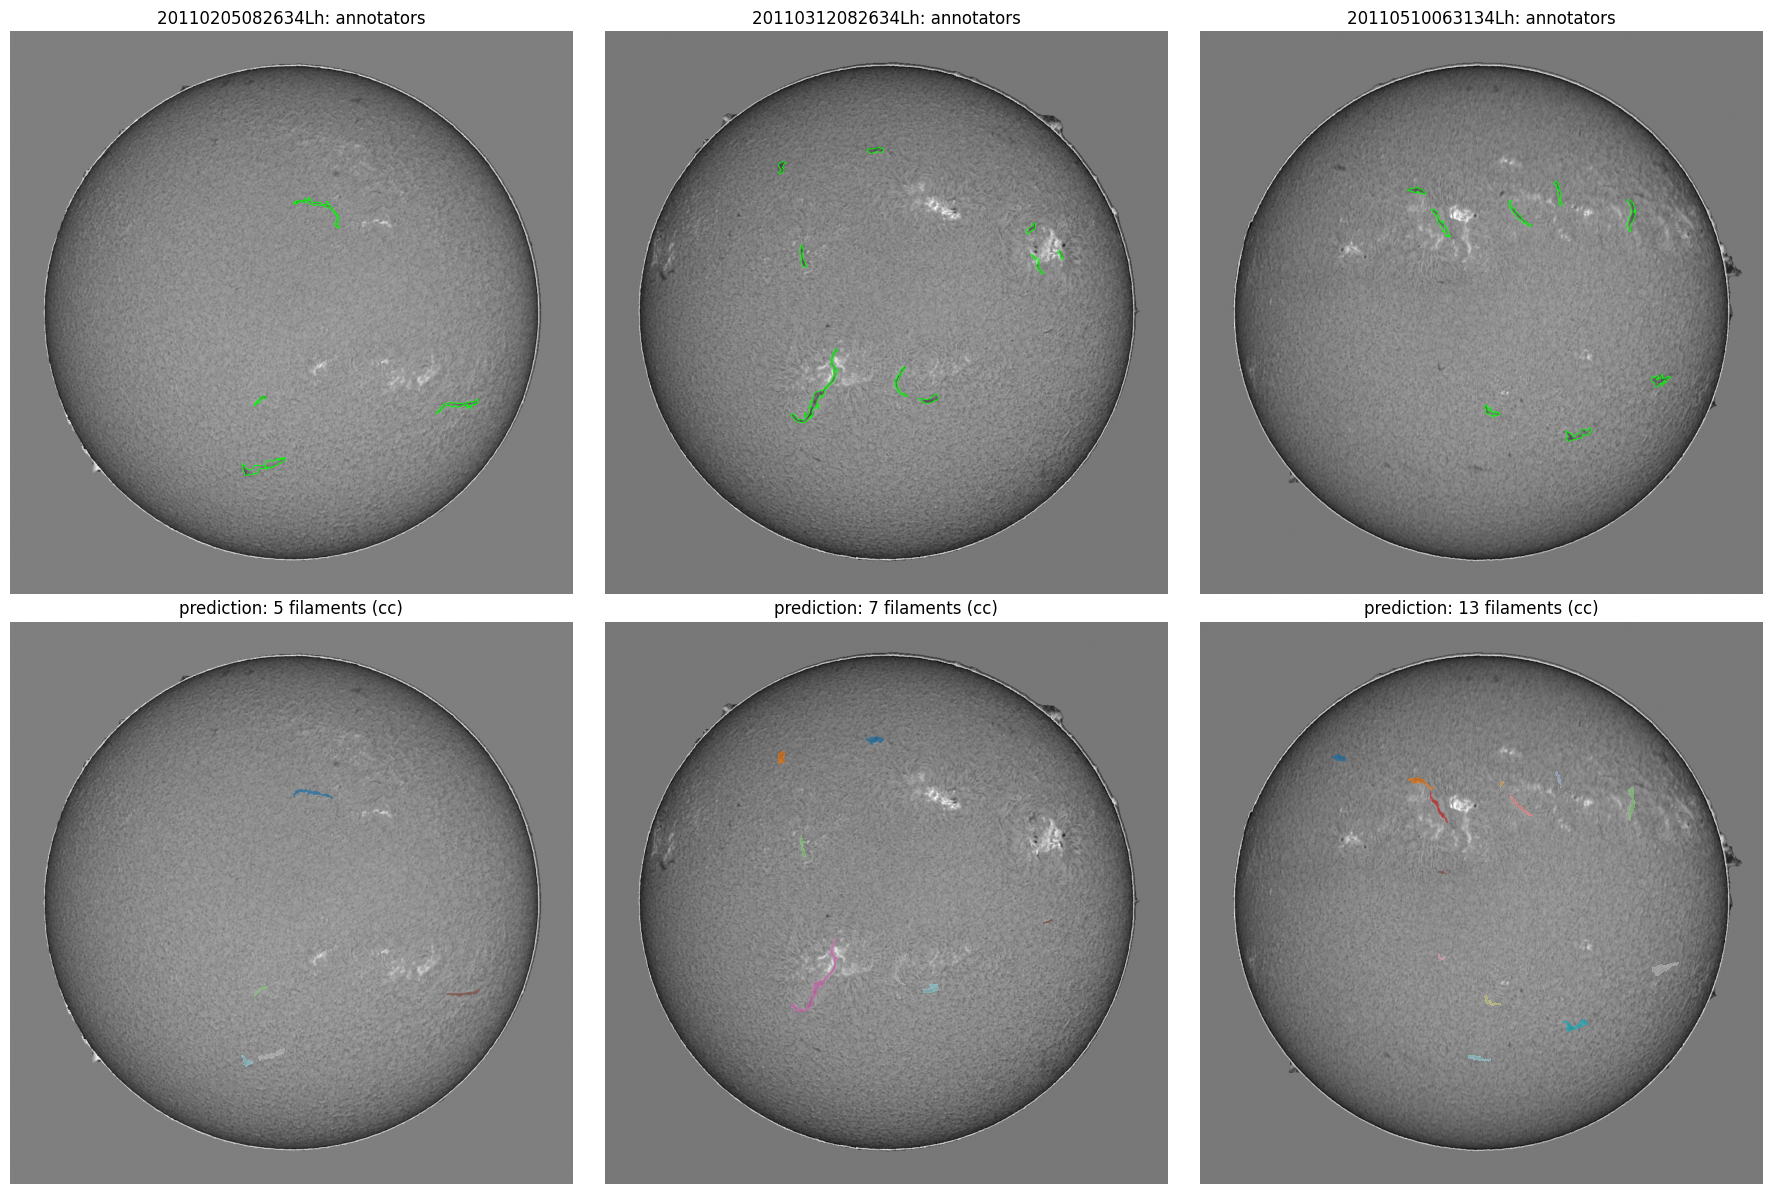

In [9]:
try:
    show = val_idx[:3]
    fig, ax = plt.subplots(2, len(show), figsize=(6 * len(show), 12), squeeze=False)
    for c, i in enumerate(show):
        lab, score = instances(*val_out[i], VALID[i], BEST["mode"], BEST["thr"])
        keep = select(score, BEST["min_score"])
        ax[0, c].imshow(IMG[i].astype(np.float32), cmap="gray"); ax[0, c].contour(SOFT[i] > 0, [0.5], colors="lime", linewidths=0.6)
        ax[0, c].set_title(f"{stems[i]}: annotators"); ax[0, c].axis("off")
        ax[1, c].imshow(IMG[i].astype(np.float32), cmap="gray")
        ax[1, c].imshow(np.ma.masked_where(~np.isin(lab, keep), lab), cmap="tab20", alpha=0.6, interpolation="nearest")
        ax[1, c].set_title(f"prediction: {len(keep)} filaments ({BEST['mode']})"); ax[1, c].axis("off")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("plot skipped:", e)